# Laboratório — Agentes Probabilísticos no Wumpus World

*Tópico I • Probabilidade condicional, distribuição conjunta e regra de Bayes*

## Ajustando o ambiente

Este laboratório usa apenas a biblioteca padrão do Python, com módulos para enumerar combinações, fazer produtos de probabilidades, gerar mundos aleatórios reprodutíveis, medir o custo da enumeração e realizar a busca em largura usada pelo agente.

In [17]:
import itertools
import math
import random
import time
from collections import Counter, deque

## Motivação

No laboratório anterior, o agente lógico usava Model Checking, Forward Chaining e DPLL para deduzir fatos com certeza a partir de uma base de conhecimento. O mundo real, porém, raramente oferece essa clareza. A **incerteza** vem de observações parciais, sensores imperfeitos, ações não determinísticas ou simplesmente da falta de conhecimento sobre o ambiente.

Considere a situação clássica do Wumpus World. O agente visitou $[1,1]$, $[1,2]$ e $[2,1]$, sentiu **brisa** em $[1,2]$ e em $[2,1]$ e nenhuma brisa em $[1,1]$. A lógica conclui apenas que:

$$P_{1,3} \lor P_{2,2} \qquad\text{e}\qquad P_{2,2} \lor P_{3,1}$$

Nenhuma das salas $[1,3]$, $[2,2]$ e $[3,1]$ pode ser **provada** segura. Para o agente lógico, as três são igualmente proibidas, o que o deixa paralisado.

![Tabuleiro 4×4 do Wumpus World com as salas [1,1], [1,2] e [2,1] visitadas. À esquerda, as salas [1,3], [2,2] e [3,1] aparecem com interrogação. À direita, aparecem com probabilidades de poço de 31%, 86% e 31%. As demais salas aparecem com 20%.](attachment:wumpus_motivacao.png)

*Salas visitadas em cinza. À esquerda, a fronteira vista pelo agente lógico. À direita, a probabilidade de poço calculada pelo agente probabilístico para cada sala desconhecida.*
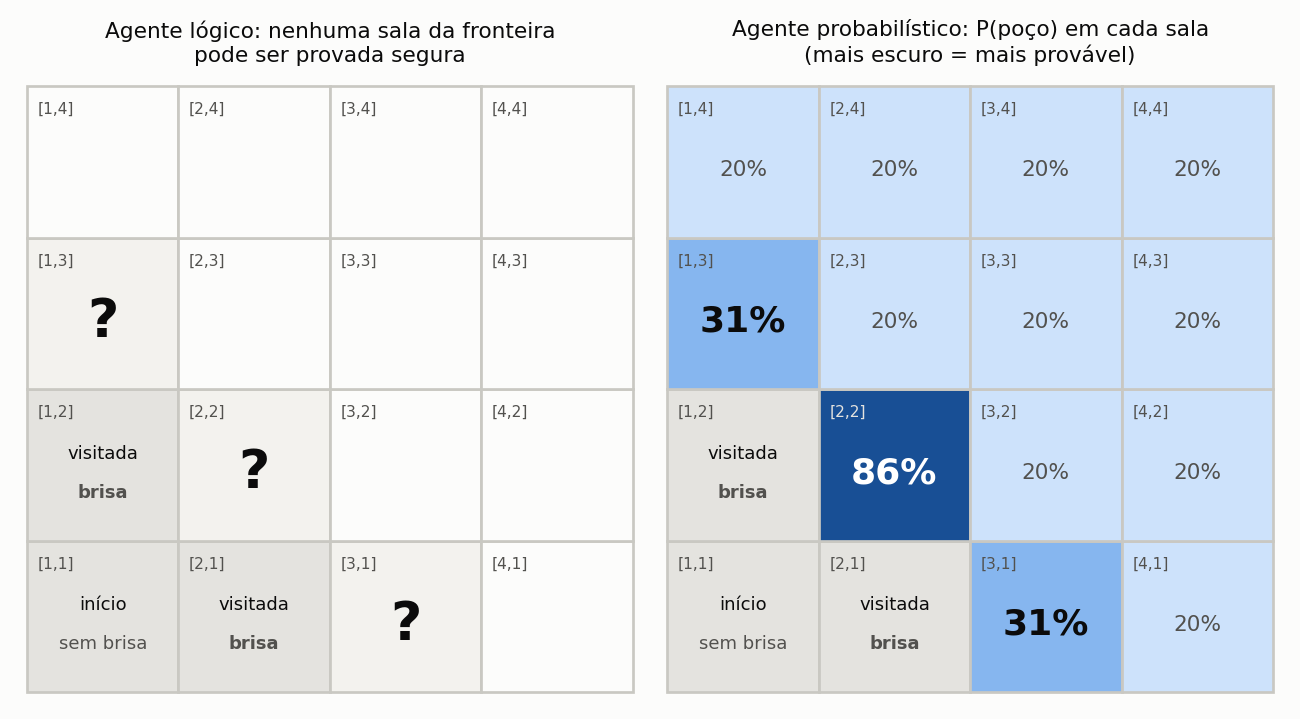

Um agente probabilístico vai além: calcula que $[2,2]$ tem cerca de **86%** de chance de conter um poço, enquanto $[1,3]$ e $[3,1]$ têm cerca de **31%**. Ao final da fundamentação teórica, você terá construído, passo a passo, todas as ferramentas necessárias para chegar a esses números.

Probabilidade sozinha, entretanto, não decide nada. A **Teoria da Decisão** combina a probabilidade (o que o agente acredita) com a **utilidade** (o que o agente deseja). Um agente racional escolhe a ação que maximiza a **utilidade esperada**, o que pode significar arriscar uma sala com 31% de perigo ou desistir e sair da caverna.

## Objetivos de aprendizagem

Ao final deste laboratório, você será capaz de:

* **Modelar o Wumpus World com variáveis aleatórias:** descrever poços e brisas como variáveis e cada configuração completa como um *mundo possível*.
* **Aplicar probabilidade condicional e a regra do produto:** interpretar o condicionamento como o descarte de mundos incompatíveis com a evidência.
* **Construir e consultar a distribuição conjunta completa:** responder perguntas por marginalização e normalização.
* **Reconhecer os limites de escala** da enumeração e explicar por que a independência, absoluta e condicional, é indispensável.
* **Usar o teorema de Bayes** para passar do modelo causal $P(\text{efeito}\mid\text{causa})$ ao diagnóstico $P(\text{causa}\mid\text{efeito})$.
* **Implementar um agente** que mantém crenças exatas sobre poços e Wumpus e escolhe ações maximizando a utilidade esperada.

## Fundamentação teórica

Antes de programar o agente, vamos construir, passo a passo, as ferramentas que ele usará para raciocinar sob incerteza. O percurso parte de uma pergunta simples: o que o agente pode afirmar sobre as salas que ainda não visitou?

Começaremos descrevendo o mundo com variáveis aleatórias e veremos como uma única observação muda as crenças do agente. Em seguida, aprenderemos a responder a qualquer pergunta a partir de todos os mundos possíveis, perceberemos por que essa estratégia não escala e descobriremos como a independência entre variáveis contorna o problema. Ao final, o teorema de Bayes fechará o percurso, mostrando como passar do que o agente observa para aquilo que ele precisa saber.

### 1. Variáveis aleatórias e mundos possíveis no Wumpus World

Toda a história começa com uma escolha: quais aspectos do mundo o agente precisa acompanhar? Para raciocinar sob incerteza, o primeiro passo é definir as **variáveis aleatórias** do domínio. 

Neste laboratório, vamos nos concentrar nos poços e nas brisas que eles provocam. Para cada sala $[x,y]$, a variável booleana $P_{x,y}$ indica se há um poço naquela sala e a variável booleana $B_{x,y}$ indica se o agente sente brisa ali. Como a sala $[1,1]$ é sempre segura, não existe variável de poço associada a ela. No tabuleiro $4\times4$ há, portanto, 15 variáveis de poço e 16 de brisa.

Com as variáveis definidas, precisamos dizer como elas se comportam. O modelo probabilístico apoia-se em duas regras. A primeira é a **prior**, ou probabilidade incondicional: cada sala, exceto $[1,1]$, contém um poço com probabilidade $P(p_{x,y}) = 0{,}2$, *independentemente* das demais. Esse valor expressa o grau de crença do agente **antes** de qualquer evidência.

A segunda é o **modelo do sensor**, de natureza causal: há brisa em $[x,y]$ **se e somente se** alguma sala vizinha contém um poço. A expressão $P(B_{x,y} \mid \text{poços vizinhos})$, lida como "a probabilidade de brisa em $[x,y]$ dados os poços vizinhos", vale, portanto, 0 ou 1, ou seja, o sensor é determinístico.

Combinando essas duas regras, já podemos descrever todas as situações possíveis. Um **mundo possível** $\omega$ é uma atribuição completa de valores a todas as variáveis consideradas. Se considerarmos apenas as salas $[1,2]$ e $[2,1]$ (as únicas que podem causar brisa em $[1,1]$), existem $2^2 = 4$ mundos possíveis. Como os poços são independentes, a probabilidade de cada mundo é o produto das priors:

$$P(\omega) = \prod_{x,y} P(P_{x,y} = \omega_{x,y}).$$

A tabela a seguir lista esses quatro mundos e suas probabilidades, junto com o valor da brisa em $[1,1]$ em cada um:

| $P_{1,2}$ | $P_{2,1}$ | $B_{1,1}$ | $P(\omega)$ |
|:---:|:---:|:---:|:---:|
| falso | falso | falso | 0,64 |
| falso | verdadeiro | verdadeiro | 0,16 |
| verdadeiro | falso | verdadeiro | 0,16 |
| verdadeiro | verdadeiro | verdadeiro | 0,04 |

### 2. Probabilidade condicional e regra do produto

#### 2.1 Probabilidade condicional

Imagine agora que o agente sente brisa em $[1,1]$. Até esse momento, ele só dispunha das probabilidades incondicionais, que expressam o grau de crença em uma proposição sem nenhuma evidência. Com a nova observação, ele passa a usar a **probabilidade condicional**. Na atualização bayesiana, chama-se **a priori** a probabilidade anterior à evidência e **a posteriori** a probabilidade atualizada. Formalmente, para quaisquer proposições $a$ e $b$:

$$P(a \mid b) = \frac{P(a \land b)}{P(b)}, \qquad P(b) > 0.$$

Observar $b$ equivale a **descartar todos os mundos em que $b$ é falso**. Entre os mundos restantes, a probabilidade de $a$ é a massa dos mundos em que $a$ e $b$ são verdadeiros dividida pela massa total dos mundos em que $b$ é verdadeiro.

Voltando ao agente que sentiu brisa em $[1,1]$, o mundo "sem poço em $[1,2]$ e sem poço em $[2,1]$" (massa 0,64) é descartado. Sobram três mundos, com massa total $0{,}36$. Essa mesma definição, rearranjada, permite decompor uma conjunção, como mostra a regra do produto a seguir.

#### 2.2 Regra do produto

A definição de probabilidade condicional também pode ser lida ao contrário. Multiplicando os dois lados por $P(b)$, obtém-se a **regra do produto**:

$$P(a \land b) = P(a \mid b)\,P(b).$$

Para variáveis aleatórias, a regra vale para cada combinação de valores: $P(X=x, Y=y) = P(X=x \mid Y=y)\,P(Y=y)$. A intuição é que, para $a$ e $b$ serem verdadeiros ao mesmo tempo, $b$ precisa ocorrer e, dado que ocorreu, $a$ também precisa ser verdadeiro.

Neste ponto, vale distinguir com cuidado dois números que costumam ser confundidos. No exemplo de $[1,1]$, o valor $P(p_{1,2} \land b_{1,1}) = 0{,}2$ é uma probabilidade *conjunta*: expressa a chance de que, no mapa, existam ao mesmo tempo um poço em $[1,2]$ e uma brisa em $[1,1]$. Como todo poço em $[1,2]$ gera brisa em $[1,1]$, esse valor coincide com a prior do poço, $1{,}0 \times 0{,}2$.

Esse número, contudo, **não** é a chance de haver poço depois de sentir a brisa. Essa outra grandeza é a probabilidade *condicional* $P(p_{1,2} \mid b_{1,1}) = 0{,}2 / 0{,}36 \approx 0{,}556$, que aumentou porque a evidência eliminou o mundo mais provável (nenhum poço, massa 0,64). Note ainda que as duas formas da regra do produto produzem o mesmo valor para a conjunção. Essa simetria é a base do teorema de Bayes.

### 3. Distribuição conjunta completa

Até aqui, olhamos para poços e brisas separadamente. Vamos agora reuni-los em um único objeto, capaz de responder a qualquer pergunta sobre o domínio: a distribuição conjunta completa. No caso discreto, ela atribui uma probabilidade $P(\omega)$ a cada mundo possível do espaço amostral $\Omega$. Essas probabilidades são não negativas e somam 1.

No Wumpus, a brisa também é uma variável aleatória. A conjunta sobre $(P_{1,2}, P_{2,1}, B_{1,1})$ tem $2^3 = 8$ entradas e é construída pela regra do produto:

$$P(p_{1,2}, p_{2,1}, b_{1,1}) = P(b_{1,1} \mid p_{1,2}, p_{2,1})\,P(p_{1,2})\,P(p_{2,1}).$$

Como o sensor é determinístico, metade das entradas vale zero: são mundos *impossíveis*, como "há poço em $[1,2]$, mas não há brisa em $[1,1]$". As oito entradas, que somam 1, são as seguintes:

| $P_{1,2}$ | $P_{2,1}$ | $B_{1,1}$ | $P(\omega)$ |
|:---:|:---:|:---:|:---:|
| falso | falso | falso | 0,64 |
| falso | falso | verdadeiro | 0 |
| falso | verdadeiro | falso | 0 |
| falso | verdadeiro | verdadeiro | 0,16 |
| verdadeiro | falso | falso | 0 |
| verdadeiro | falso | verdadeiro | 0,16 |
| verdadeiro | verdadeiro | falso | 0 |
| verdadeiro | verdadeiro | verdadeiro | 0,04 |

Essa tabela é poderosa porque tem a propriedade de **completude semântica**: a probabilidade de **qualquer** proposição $\varphi$ é a soma das probabilidades dos mundos em que ela é verdadeira:

$$P(\varphi) = \sum_{\omega \models \varphi} P(\omega).$$

Assim, a distribuição conjunta completa funciona como uma **base de conhecimento**: com ela é possível responder a qualquer pergunta probabilística sobre as variáveis do domínio, desde que os condicionamentos envolvidos tenham probabilidade positiva.

### 4. Inferência por marginalização e normalização

#### 4.1 Marginalização

Com a conjunta em mãos, a primeira pergunta natural é: qual a probabilidade de uma única variável, ignorando as demais? A resposta vem de somar as probabilidades sobre os valores das variáveis que não interessam. Formalmente, somar sobre os valores de uma variável, ou de um conjunto de variáveis $Z$, fornece a distribuição marginal de $Y$. Essa operação é chamada **marginalização** (*summing out*):

$$P(Y=y) = \sum_z P(Y=y, Z=z).$$

Aplicando a regra do produto a cada termo dessa soma, obtém-se a **lei da probabilidade total**, que decompõe a marginal por condicionamento:

$$P(Y=y) = \sum_z P(Y=y \mid Z=z)\,P(Z=z).$$

No Wumpus, somando as entradas da distribuição conjunta sobre $(P_{1,2}, P_{2,1}, B_{1,1})$ em que há brisa, obtém-se $P(b_{1,1}) = 0{,}16 + 0{,}16 + 0{,}04 = 0{,}36$, o mesmo valor que a probabilidade total fornece ao ponderar $P(b_{1,1} \mid z)$ pela prior de cada configuração $z$ dos poços. É também a marginalização que elimina as variáveis ocultas em uma consulta, como mostra a normalização a seguir.

#### 4.2 Normalização

Na maioria das vezes, porém, a pergunta do agente envolve evidência: dado o que observei, qual a chance de haver poço aqui? Para uma variável de consulta $X$, dada a evidência $E=e$ e as variáveis ocultas $Y$, a inferência se resume a uma **normalização**:

$$P(X \mid e) = \alpha\,P(X, e) = \alpha \sum_y P(X, e, y).$$

O fator $\alpha = 1/P(e)$, com $P(e) > 0$, garante que a distribuição resultante some 1. Na prática, nem precisamos calcular $P(e)$ separadamente: basta calcular os termos não normalizados para cada valor de $X$ e dividir pela soma deles.

Com essa ferramenta, podemos finalmente voltar ao impasse do agente lógico, que visitou $[1,1]$, $[1,2]$ e $[2,1]$ sem conseguir provar que alguma sala vizinha é segura. A evidência disponível tem duas partes. As salas visitadas estão, por isso mesmo, livres de poço ($\lnot p_{1,1}, \lnot p_{1,2}, \lnot p_{2,1}$). As brisas observadas são $\lnot b_{1,1}$, $b_{1,2}$ e $b_{2,1}$.

A consulta é $P(P_{1,3} \mid \text{evidência})$, cujas variáveis ocultas são os poços nas outras 12 salas desconhecidas. Enumerando os $2^{13}$ mundos sobre as 13 salas desconhecidas e descartando os incompatíveis com as brisas observadas, obtém-se o vetor não normalizado $\langle 0{,}072;\ 0{,}16 \rangle$ para $P_{1,3}$. Normalizado por $\alpha = 1/0{,}232 \approx 4{,}31$, ele resulta em $P(p_{1,3} \mid \text{evidência}) \approx 0{,}31$. Pelo mesmo procedimento, $P(p_{3,1} \mid \text{evidência}) \approx 0{,}31$ e $P(p_{2,2} \mid \text{evidência}) \approx 0{,}86$. O fator $P(\lnot p_{1,1}, \lnot p_{1,2}, \lnot p_{2,1})$ é o mesmo em todos os termos e, portanto, é absorvido por $\alpha$.

Por que $[2,2]$ fica tão acima das outras duas? A sala $[2,2]$ é vizinha de **ambas** as salas com brisa, de modo que um único poço ali explica as duas observações. Explicá-las sem $[2,2]$ exigiria dois poços, em $[1,3]$ e em $[3,1]$, o que é bem menos provável ($0{,}2^2$). Daí os **86%**. Já $[1,3]$ e $[3,1]$ ficam em **31%**: mais que a prior de 20%, porque cada uma pode explicar uma das brisas, mas muito menos que $[2,2]$.

O resultado depende de *toda* a evidência. Usar apenas $b_{1,2}$, como na conta ingênua $0{,}2/0{,}36$, daria 55,6% para $[1,3]$, ignorando que $[2,2]$ já explica a brisa. Observe também que o vetor não normalizado é proporcional a $P(X, e)$. Dividi-lo pela soma, isto é, multiplicá-lo por $\alpha$, transforma-o em $P(X \mid e)$.

### 5. Limites de escala da tabela conjunta

A enumeração resolveu o impasse, mas a um custo que cresce depressa. Com $n$ variáveis booleanas, a tabela conjunta tem $2^n$ entradas e a inferência por enumeração cresce no mesmo ritmo: a consulta com 13 salas desconhecidas já percorre 8.192 mundos, enquanto um tabuleiro $10\times10$, com 99 variáveis de poço, exigiria mais tempo que a idade do universo e uma quantidade impraticável de dados para estimar cada entrada. A saída é **explorar a estrutura do domínio**, em particular as relações de independência entre as variáveis.

![Gráfico em escala logarítmica do tempo para enumerar 2^n mundos em função de n, cruzando as linhas de 1 segundo, 1 dia, 1 ano e a idade do universo. Com n = 13 o tempo é de cerca de 0,02 s, com n = 64 é de cerca de um milhão de anos e com n = 100, de cerca de 10^17 anos.](attachment:escala_enumeracao.png)

*Cada variável a mais dobra o tempo. A reta em escala logarítmica cruza a idade do universo antes de n = 80.*
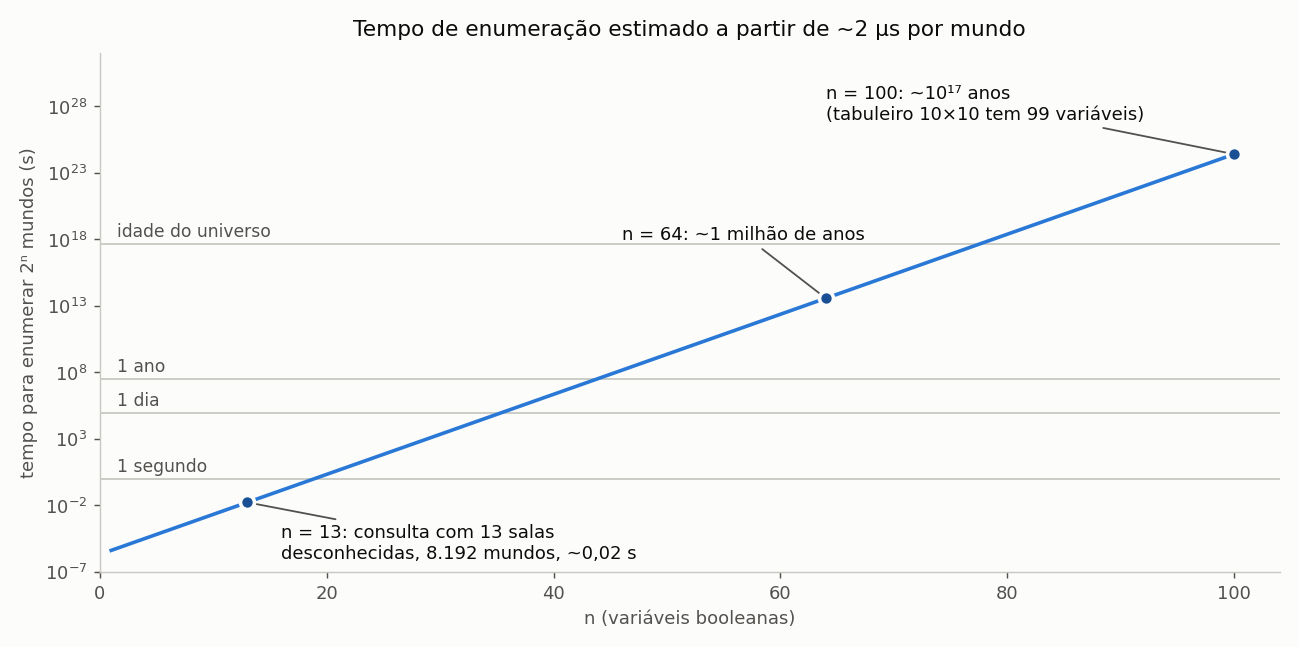

### 6. Independência absoluta e condicional

Felizmente, o mundo do Wumpus tem uma estrutura que podemos aproveitar. Duas variáveis são **independentes** quando conhecer uma não altera a crença sobre a outra, isto é, quando $P(X, Y) = P(X)\,P(Y)$. São **condicionalmente independentes** dado $Z$ quando isso só vale depois de fixar $Z$, ou seja, quando $P(X, Y \mid Z) = P(X \mid Z)\,P(Y \mid Z)$. 

No Wumpus, os poços são independentes por construção, mas as brisas em $[1,2]$ e $[2,1]$ não são: ambas podem ser causadas por um poço em $[2,2]$ e, por isso, uma torna a outra mais provável. Fixado $P_{2,2}$, essa associação desaparece. É essa independência condicional que permite ao agente raciocinar apenas sobre as salas da fronteira, ignorando o restante do tabuleiro. A independência mostra como simplificar o modelo, mas não como usá-lo na direção de que o agente precisa: o modelo descreve $P(\text{brisa} \mid \text{poço})$, enquanto o agente quer $P(\text{poço} \mid \text{brisa})$. Essa inversão é o papel do teorema de Bayes.

![À esquerda, grafo causal em que P1,3 e P2,2 apontam para B1,2 enquanto P2,2 e P3,1 apontam para B2,1, com P2,2 destacado como causa comum. À direita, tabuleiro 4×4 com [1,1], [1,2] e [2,1] visitadas, [1,3], [2,2] e [3,1] marcadas como fronteira e as demais salas fora da soma.](attachment:independencia_fronteira.png)

*A causa comum associa as brisas. Fixados os poços da fronteira, as demais salas não influenciam a evidência e saem da soma.*
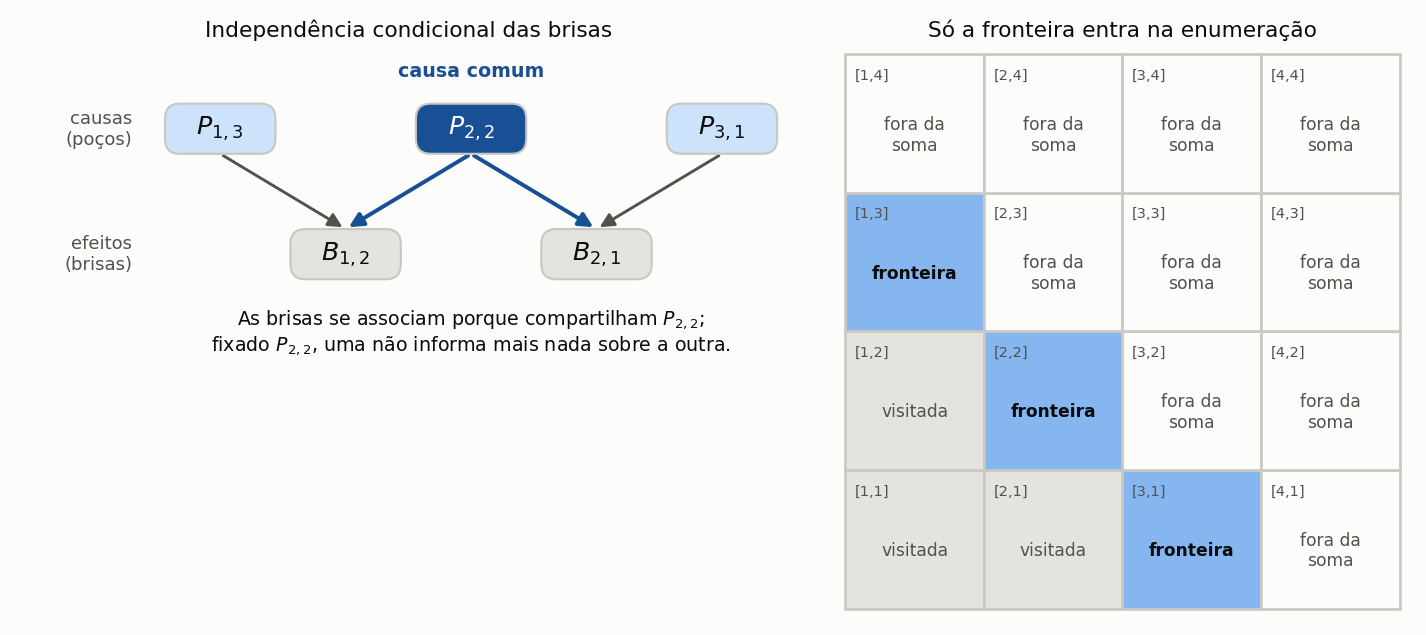

### 7. Teorema de Bayes e raciocínio causal × diagnóstico

#### 7.1 Derivação do teorema

Resta um último passo. O modelo descreve como poços produzem brisas, mas o agente precisa raciocinar no sentido contrário. Para inverter essa direção, partimos de uma observação simples: a conjunção é simétrica ($a \land b \equiv b \land a$), então a regra do produto pode ser escrita de duas formas:

$$P(a \land b) = P(a \mid b)\,P(b) = P(b \mid a)\,P(a).$$

Igualando os lados direitos e dividindo por $P(a)$, obtém-se o **teorema de Bayes**:

$$P(b \mid a) = \frac{P(a \mid b)\,P(b)}{P(a)}, \qquad P(a) > 0.$$

O resultado é simples, mas poderoso: ele permite **inverter** uma probabilidade condicional, obtendo $P(b \mid a)$ a partir de $P(a \mid b)$, que muitas vezes é a grandeza conhecida ou mais fácil de estimar.

#### 7.2 Os termos do teorema

Para usar o teorema com segurança, vale dar nome a cada uma de suas partes. Escrito com uma hipótese (a causa) e uma evidência (o efeito observado), ele fica:

$$\underbrace{P(\text{Causa} \mid \text{Efeito})}_{\text{posterior}} = \frac{\overbrace{P(\text{Efeito} \mid \text{Causa})}^{\text{verossimilhança}}\;\overbrace{P(\text{Causa})}^{\text{prior}}}{\underbrace{P(\text{Efeito})}_{\text{evidência}}}$$

* **Prior**, $P(\text{Causa})$: grau de crença na hipótese **antes** de observar a evidência. No Wumpus, $P(p_{1,2}) = 0{,}2$.
* **Verossimilhança**, $P(\text{Efeito} \mid \text{Causa})$: quão compatível a evidência é com cada valor da hipótese. Vista como função da hipótese, não é uma distribuição e não precisa somar 1. No Wumpus, vem do modelo do sensor: $P(b_{1,1} \mid p_{1,2}) = 1$ e $P(b_{1,1} \mid \lnot p_{1,2}) = P(p_{2,1}) = 0{,}2$, porque sem poço em $[1,2]$ a brisa só pode vir de $[2,1]$.
* **Evidência**, ou verossimilhança marginal, $P(\text{Efeito})$: probabilidade total de observar a evidência, somando sobre todos os valores da hipótese, $P(e) = \sum_h P(e \mid h)\,P(h)$, pela lei da probabilidade total. Não depende da hipótese e funciona como constante de normalização. No Wumpus, $P(b_{1,1}) = 1 \times 0{,}2 + 0{,}2 \times 0{,}8 = 0{,}36$.
* **Posterior**, $P(\text{Causa} \mid \text{Efeito})$: grau de crença na hipótese **depois** de observar a evidência, que é o que o agente quer calcular. No Wumpus, $P(p_{1,2} \mid b_{1,1})$.

Juntando os termos, $P(p_{1,2} \mid b_{1,1}) = 1 \times 0{,}2 / 0{,}36 \approx 0{,}556$, exatamente o valor obtido ao descartar os mundos sem brisa e renormalizar os restantes.

#### 7.3 Forma normalizada

Na prática, há um atalho. Como a evidência não depende da hipótese, nem é preciso calculá-la separadamente. Para um valor observado $x$, o teorema pode ser escrito na **forma normalizada**:

$$P(Y \mid X=x) = \alpha\,P(X=x \mid Y)\,P(Y), \qquad \alpha = 1/P(X=x).$$

Basta multiplicar verossimilhança e prior para cada valor de $Y$ e dividir pela soma dos resultados, o mesmo procedimento de normalização usado na inferência por enumeração. No Wumpus, com $Y = P_{1,2}$ e $X = B_{1,1}$, o vetor não normalizado é $\langle 1 \times 0{,}2;\ 0{,}2 \times 0{,}8 \rangle = \langle 0{,}2;\ 0{,}16 \rangle$. Dividindo-o pela soma, $0{,}36$, obtém-se a posterior $\langle 0{,}556;\ 0{,}444 \rangle$.

#### 7.4 Raciocínio causal e diagnóstico

Com o teorema em mãos, vale olhar com atenção para as duas direções que o raciocínio pode seguir em um modelo com interpretação causal. O raciocínio **causal**, ou preditivo, vai da causa para o efeito, $P(\text{Efeito} \mid \text{Causa})$: no Wumpus, $P(\text{brisa} \mid \text{poço vizinho}) = 1$. No exemplo médico do material, um modelo hipotético adota $P(s \mid m) = 0{,}7$, com $s$ = rigidez no pescoço e $m$ = meningite (número ilustrativo).

O raciocínio **diagnóstico** segue o sentido inverso, do efeito para a causa, $P(\text{Causa} \mid \text{Efeito})$. É o que o agente realmente deseja conhecer: a chance de poço, dada a brisa. O teorema de Bayes é justamente a ponte entre as duas direções: a verossimilhança expressa o conhecimento causal e a posterior, o diagnóstico.

#### 7.5 Robustez do modelo causal

Por que o agente guarda o modelo causal, e não o diagnóstico? Porque os modelos causais tendem a ser mais robustos. A probabilidade diagnóstica depende da prior da causa e muda quando a frequência da causa se altera (como durante uma epidemia, na medicina, ou em uma caverna com mais poços, no Wumpus), mesmo que o mecanismo $P(\text{efeito} \mid \text{causa})$ permaneça igual. A tabela a seguir mostra esse efeito ao variar a prior de poço em $[1,2]$ e $[2,1]$.

| prior $P(p)$ | $P(b_{1,1} \mid p_{1,2})$ | $P(p_{1,2} \mid b_{1,1})$ |
|:---:|:---:|:---:|
| 0,05 | 1,00 | 0,513 |
| 0,10 | 1,00 | 0,526 |
| 0,20 | 1,00 | 0,556 |
| 0,40 | 1,00 | 0,625 |

O conhecimento causal ficou **estável** (sempre 1,0), enquanto o diagnóstico **mudou** com a prior. Por isso, é vantajoso armazenar o modelo causal e derivar o diagnóstico via Bayes: ao mudar a caverna, basta atualizar a prior.

Essa estabilidade, porém, **não é automática**. Mudanças populacionais, intervenções ou alterações no sensor (uma brisa que às vezes falha, por exemplo) também podem modificar $P(\text{efeito} \mid \text{causa})$.

Vale ainda uma distinção importante: uma probabilidade condicional, por si só, não demonstra causalidade. Aqui, a leitura "poço **causa** brisa" vem das regras do jogo, isto é, de uma hipótese sobre o processo que gera os dados, e não das probabilidades.

## Implementação

Com a teoria construída, chegou a hora de montar o agente passo a passo. Vamos começar definindo as funções básicas que traduzem o modelo do Wumpus para código. Em seguida, usaremos essas funções para reproduzir os três cálculos de que o agente depende para formar crenças.

Depois disso, construiremos o agente em camadas, cada uma em sua própria subseção. O **ambiente** gera mundos coerentes com o modelo probabilístico. As **crenças** calculam probabilidades exatas de poço e de Wumpus. O **mapa mental** mostra o que o agente sabe e o que acredita. A **decisão** escolhe a ação de maior utilidade esperada. Por fim, o **ciclo completo** junta todas as peças.

### Modelo do mundo

Nesta primeira etapa, vamos definir as funções que todas as outras partes do laboratório usam. Elas formalizam o modelo probabilístico do Wumpus, no qual cada sala, exceto $[1,1]$, contém um poço com probabilidade 0,2, independentemente das demais.

Algumas funções descrevem a geometria do tabuleiro, como a lista de salas e as vizinhas de cada uma. Outras traduzem o modelo para código: calculam a probabilidade de um mundo como o produto das priors, geram todos os mundos possíveis sobre um conjunto de salas e implementam o modelo do sensor, segundo o qual há brisa se e somente se alguma vizinha tem poço. Salas fora do mundo enumerado são tratadas como sem poço, o que é correto quando elas são sabidamente seguras.

Duas funções sustentam toda a inferência: uma verifica se um mundo reproduz as brisas observadas e a outra calcula a probabilidade de uma proposição somando os mundos em que ela é verdadeira. A célula abaixo começa fixando os parâmetros do modelo (tabuleiro $4\times4$, prior de poço 0,2 e sala inicial $[1,1]$) e, em seguida, define essas funções. Por isso, ela não produz saída.

In [18]:
# Parâmetros do modelo
GRID_SIZE = 4    # tabuleiro 4x4
PIT_PROB = 0.2   # probabilidade a priori de poço em cada sala, exceto [1,1]
START = (1, 1)   # sala inicial, sempre segura

def all_cells(n=GRID_SIZE):
    # Todas as salas (coluna, linha) do tabuleiro
    return [(x, y) for y in range(1, n + 1) for x in range(1, n + 1)]

def neighbors(cell, n=GRID_SIZE):
    # Salas adjacentes (leste, oeste, norte, sul) dentro dos limites do tabuleiro
    x, y = cell
    candidates = [(x + 1, y), (x - 1, y), (x, y + 1), (x, y - 1)]
    return [(a, b) for a, b in candidates if 1 <= a <= n and 1 <= b <= n]

def room_label(cell):
    # Rótulo da sala no mesmo formato do texto, [x,y]
    return f"[{cell[0]},{cell[1]}]"

def world_prob(world, prior=PIT_PROB):
    # P(ω): produto das priors, pois os poços são independentes
    return math.prod(prior if pit else 1 - prior for pit in world.values())

def enumerate_worlds(cells, prior=PIT_PROB):
    # Gera todos os mundos possíveis (atribuições de poço às salas em `cells`) e suas probabilidades
    for values in itertools.product([False, True], repeat=len(cells)):
        world = dict(zip(cells, values))
        yield world, world_prob(world, prior)

def breeze(world, cell):
    # Modelo do sensor: há brisa em `cell` se e somente se alguma vizinha tem poço
    return any(world.get(nb, False) for nb in neighbors(cell))

def prob(phi, cells, prior=PIT_PROB):
    # P(φ) = soma de P(ω) sobre os mundos em que φ é verdadeira
    return sum(p for world, p in enumerate_worlds(cells, prior) if phi(world))

def consistent(world, breezes):
    # Verifica se o mundo reproduz todas as brisas observadas
    return all(breeze(world, c) == b for c, b in breezes.items())

### Da teoria aos cenários

Antes de montar o agente, vamos usar essas funções para reproduzir os três cálculos de que ele depende. Primeiro, aplicaremos o teorema de Bayes à brisa sentida na sala inicial. Depois, resolveremos o impasse das três salas ambíguas usando toda a evidência. Por último, veremos que o mesmo resultado é obtido enumerando apenas a fronteira, que é exatamente como o agente calcula suas crenças a cada passo. Assim, quando chegarmos aos cenários, os números que aparecerem já serão familiares.

#### Forma normalizada de Bayes

Vamos começar pelo caso mais simples. O agente está em $[1,1]$ e sente brisa, e queremos saber a probabilidade de haver poço em $[1,2]$. Para isso, a célula abaixo multiplica a verossimilhança da brisa pela prior de cada valor de $P_{1,2}$ e, em seguida, normaliza o resultado. Observe na saída que a posterior chega a cerca de 0,556 sem que a evidência precise ser calculada separadamente.

In [19]:
# Forma normalizada de Bayes: posterior ∝ verossimilhança × prior
prior_p12 = {True: PIT_PROB, False: 1 - PIT_PROB}
likelihood_b11 = {True: 1.0, False: PIT_PROB}   # P(b1,1 | P1,2): modelo causal

unnorm = {y: likelihood_b11[y] * prior_p12[y] for y in (True, False)}
alpha = 1 / sum(unnorm.values())
posterior = {y: alpha * u for y, u in unnorm.items()}

print(f"Prior          P(P1,2)          = <{prior_p12[True]:.2f}, {prior_p12[False]:.2f}>")
print(f"Verossimilhança P(b1,1 | P1,2)  = <{likelihood_b11[True]:.2f}, {likelihood_b11[False]:.2f}>")
print(f"Não normalizado                 = <{unnorm[True]:.2f}, {unnorm[False]:.2f}>   α = 1/{sum(unnorm.values()):.2f}")
print(f"Posterior      P(P1,2 | b1,1)   = <{posterior[True]:.4f}, {posterior[False]:.4f}>")

Prior          P(P1,2)          = <0.20, 0.80>
Verossimilhança P(b1,1 | P1,2)  = <1.00, 0.20>
Não normalizado                 = <0.20, 0.16>   α = 1/0.36
Posterior      P(P1,2 | b1,1)   = <0.5556, 0.4444>


#### Inferência por normalização com toda a evidência

Agora vamos ao impasse do agente lógico. O agente visitou $[1,1]$, $[1,2]$ e $[2,1]$ e sentiu brisa apenas nas duas últimas. Queremos calcular $P(P_{1,3} \mid \text{evidência})$. A célula abaixo enumera os $2^{13}$ mundos possíveis sobre as salas desconhecidas, descarta os incompatíveis com as brisas observadas e normaliza os termos restantes por $\alpha = 1/P(e)$. O cálculo é repetido para $[1,3]$, $[2,2]$ e $[3,1]$. Na saída, você verá cerca de 31% para $[1,3]$ e $[3,1]$ e 86% para $[2,2]$.

In [20]:
# Salas visitadas (sem poço) e brisas observadas nelas
aima_safe = [(1, 1), (1, 2), (2, 1)]
aima_breezes = {(1, 1): False, (1, 2): True, (2, 1): True}

# Variáveis ocultas: todas as salas que não estão entre as visitadas
unknown = [c for c in all_cells() if c not in aima_safe]   # as 13 salas desconhecidas
evidence = lambda w: consistent(w, aima_breezes)

for cell in [(1, 3), (2, 2), (3, 1)]:
    # Termos não normalizados P(P_cell, e), depois normalização por α = 1/P(e)
    unnorm = {v: prob(lambda w: w[cell] == v and evidence(w), unknown) for v in (True, False)}
    alpha = 1 / sum(unnorm.values())
    # Mostra o vetor não normalizado, o fator α e a posterior P(poço | e)
    print(f"P(P{cell[0]},{cell[1]} | e): não normalizado <{unnorm[True]:.5f}, {unnorm[False]:.5f}>"
          f"  ->  α = {alpha:.2f}  ->  P(poço) = {alpha * unnorm[True]:.3f}"
          f"   ({2 ** len(unknown)} mundos enumerados)")

P(P1,3 | e): não normalizado <0.07200, 0.16000>  ->  α = 4.31  ->  P(poço) = 0.310   (8192 mundos enumerados)
P(P2,2 | e): não normalizado <0.20000, 0.03200>  ->  α = 4.31  ->  P(poço) = 0.862   (8192 mundos enumerados)
P(P3,1 | e): não normalizado <0.07200, 0.16000>  ->  α = 4.31  ->  P(poço) = 0.310   (8192 mundos enumerados)


#### Consulta restrita à fronteira

Enumerar 8.192 mundos funciona neste tabuleiro, mas não escala. Vamos, então, repetir a mesma consulta de duas maneiras: primeiro com todas as 13 salas desconhecidas e depois apenas com a fronteira mais a sala consultada. A tabela de saída compara, para cada sala, a probabilidade obtida e o número de mundos examinados em cada caso.

In [21]:
# Consulta P(poço | evidência) restrita à fronteira
# Fronteira: salas desconhecidas vizinhas de alguma sala visitada
frontier = sorted({nb for c in aima_breezes for nb in neighbors(c)} - set(aima_safe))

print(f"{'sala':>6} | {'P_completa':>9} {'mundos':>7} | {'P_fronteira':>9} {'mundos':>7} | fronteira usada")
print("-" * 72)
for cell in [(1, 3), (2, 2), (3, 1), (4, 4)]:
    local = sorted(set(frontier) | {cell})   # fronteira mais a sala consultada
    # Mesma consulta P(P_cell | e) sobre as 13 salas e sobre a fronteira apenas
    full = prob(lambda w: w[cell] and evidence(w), unknown) / prob(evidence, unknown)
    fast = prob(lambda w: w[cell] and evidence(w), local) / prob(evidence, local)
    # A independência condicional garante que os dois resultados coincidem
    assert abs(full - fast) < 1e-12
    used = ", ".join(room_label(c) for c in local if c != cell)
    print(f"{room_label(cell):>6} | {full:>9.3f} {2 ** len(unknown):>7} | {fast:>9.3f} {2 ** len(local):>7} | {used}")

  sala | P_completa  mundos | P_fronteira  mundos | fronteira usada
------------------------------------------------------------------------
 [1,3] |     0.310    8192 |     0.310       8 | [2,2], [3,1]
 [2,2] |     0.862    8192 |     0.862       8 | [1,3], [3,1]
 [3,1] |     0.310    8192 |     0.310       8 | [1,3], [2,2]
 [4,4] |     0.200    8192 |     0.200      16 | [1,3], [2,2], [3,1]


<details>
<summary>Explicação</summary>

As duas colunas de probabilidade são idênticas em todas as linhas, mas o esforço é muito diferente. A enumeração completa percorre os $2^{13} = 8.192$ mundos das salas desconhecidas, enquanto a versão restrita examina apenas 8 mundos para $[1,3]$, $[2,2]$ e $[3,1]$. Para cada uma delas, bastam as outras duas salas da fronteira mais a própria sala consultada, ou seja, $2^3$ combinações.

A igualdade não é coincidência. As brisas observadas dependem apenas dos poços vizinhos às salas visitadas, de modo que as demais salas não alteram a compatibilidade de nenhum mundo com a evidência. Ao somar sobre elas, suas priors totalizam 1 e desaparecem da conta, sem mudar a posterior.

A sala $[4,4]$ ilustra o caso extremo. Como não é vizinha de nenhuma sala visitada, a evidência nada diz sobre ela, e a posterior volta à prior de **0,2**. Ali são enumerados 16 mundos, porque $[4,4]$ se soma às três salas da fronteira.

O custo da inferência passa, portanto, a depender do tamanho da fronteira, e não do tamanho do tabuleiro. É assim que o agente recalcula suas crenças a cada passo.

</details>

### Ambiente

Com o modelo pronto, vamos construir o mundo em que o agente vai agir. Faremos isso de duas formas. A primeira monta um mundo a partir das posições que escolhermos para poços, Wumpus e ouro e calcula as percepções de cada sala (brisa, fedor e brilho). Ela será usada nos cenários construídos à mão.

A segunda sorteia um mundo **seguindo o modelo**: cada sala, exceto $[1,1]$, recebe um poço com probabilidade 0,2, independentemente das demais. O Wumpus é único e ocupa uma posição sorteada uniformemente. O ouro fica em uma sala sem poço e sem Wumpus. O sorteio usa uma semente própria, o que garante que o mesmo mundo seja gerado sempre que repetirmos a execução. A célula abaixo também define uma função que imprime o gabarito, isto é, a posição real dos elementos ocultos.

In [22]:
def make_world(pits, wumpus, gold, n=GRID_SIZE):
    # Monta o mundo físico a partir das posições dos elementos e calcula as percepções
    world = {}
    for cell in all_cells(n):
        world[cell] = {
            "pit": cell in pits,
            "wumpus": cell == wumpus,
            "glitter": cell == gold,
            # Brisa e fedor dependem do que existe nas salas vizinhas
            "breeze": any(nb in pits for nb in neighbors(cell, n)),
            "stench": wumpus in neighbors(cell, n),
        }
    return world

def create_wumpus_world(n=GRID_SIZE, pit_prob=PIT_PROB, seed=None):
    # Sorteia um mundo coerente com o modelo: poços Bernoulli(pit_prob) e um único Wumpus uniforme
    rng = random.Random(seed)
    candidates = [c for c in all_cells(n) if c != START]
    pits = {c for c in candidates if rng.random() < pit_prob}
    wumpus = rng.choice(candidates)
    # O ouro fica em uma sala livre de poço e de Wumpus
    gold = rng.choice([c for c in candidates if c not in pits and c != wumpus])
    return make_world(pits, wumpus, gold, n)

def describe_world(world):
    # Gabarito do professor: posições reais dos elementos ocultos
    find = lambda key: [c for c, v in world.items() if v[key]]
    fmt = lambda cs: ", ".join(room_label(c) for c in cs) or "nenhum"
    print("[GABARITO DO PROFESSOR]")
    print(f"  Wumpus: {fmt(find('wumpus'))}")
    print(f"  Ouro:   {fmt(find('glitter'))}")
    print(f"  Poços:  {fmt(find('pit'))}")

> **Por que Bernoulli?** Se o gerador colocasse sempre *exatamente* 2 poços, os poços deixariam de ser independentes (saber que há um poço em $[1,3]$ reduziria a chance nas outras salas) e as posteriores calculadas pelo agente não corresponderiam ao ambiente. Por simplicidade, o Wumpus é sorteado independentemente dos poços e pode, raramente, dividir a sala com um deles.

### Crenças do agente

Nesta etapa, vamos dar ao agente a capacidade de formar crenças. Tudo o que ele sabe são as salas que visitou e as percepções que registrou em cada uma. A partir disso, calcularemos três crenças para cada sala ainda não visitada.

A primeira é a probabilidade de poço, calculada de forma exata. O cálculo começa com uma **dedução lógica**: vizinhas de salas sem brisa são certamente seguras, pois os mundos que as contrariam teriam probabilidade zero de qualquer forma. Em seguida, a parte restante da fronteira é enumerada **uma única vez** e normalizada, enquanto as salas fora da fronteira mantêm a prior.

A segunda crença, a probabilidade de Wumpus, é ainda mais simples. Como há exatamente um Wumpus, uniforme entre as 15 salas, basta descartar as posições incompatíveis com os fedores observados e com as salas visitadas, onde o agente sobreviveu. A posterior fica uniforme entre as $k$ posições restantes, isto é, $1/k$.

A terceira crença combina as duas anteriores no **risco de morte**. Como poço e Wumpus são sorteados independentemente:

$$P(\text{morte em } c) = 1 - \big(1 - P(\text{poço em } c)\big)\big(1 - P(\text{Wumpus em } c)\big).$$

A célula abaixo define as três funções de crença, que serão usadas em todos os cenários.

In [23]:
def pit_beliefs(visited, percepts, prior=PIT_PROB):
    # P(poço) exata para cada sala não visitada, com uma única enumeração da fronteira
    breezes = {c: percepts[c]["breeze"] for c in visited}
    frontier = {nb for c in visited for nb in neighbors(c)} - set(visited)
    # Dedução lógica: vizinhas de salas sem brisa não têm poço (mundos de probabilidade zero)
    safe = {nb for c in visited if not breezes[c] for nb in neighbors(c)}
    uncertain = sorted(frontier - safe)

    # Acumula P(e) em `total` e P(poço em c, e) em `unnorm_pit[c]` numa só passada
    unnorm_pit = dict.fromkeys(uncertain, 0.0)
    total = 0.0
    for world, p in enumerate_worlds(uncertain, prior):
        if consistent(world, breezes):
            total += p
            for c in uncertain:
                if world[c]:
                    unnorm_pit[c] += p

    pit = {c: prior for c in all_cells() if c not in visited}   # fora da fronteira: prior
    pit.update({c: 0.0 for c in frontier & safe})
    # Normalização: divide cada termo por P(e)
    pit.update({c: unnorm_pit[c] / total for c in uncertain})
    return pit

def wumpus_beliefs(visited, percepts):
    # P(Wumpus) exata: um único Wumpus, uniforme entre as salas diferentes de [1,1]
    # Candidatas: posições não visitadas compatíveis com o fedor (ou a falta dele) em cada sala visitada
    candidates = [c for c in all_cells() if c != START and c not in visited
                  and all(percepts[v]["stench"] == (c in neighbors(v)) for v in visited)]
    return {c: (1 / len(candidates) if c in candidates else 0.0)
            for c in all_cells() if c not in visited}

def beliefs(visited, percepts):
    # Probabilidades de poço, de Wumpus e de morte para cada sala não visitada
    pit = pit_beliefs(visited, percepts)
    wumpus = wumpus_beliefs(visited, percepts)
    # Sobreviver exige não haver poço nem Wumpus (eventos independentes)
    death = {c: 1 - (1 - pit[c]) * (1 - wumpus[c]) for c in pit}
    return pit, wumpus, death

<details>
<summary>Explicação</summary>

A enumeração aplica diretamente a independência condicional: dados os poços da fronteira, as brisas não dependem das demais salas, que por isso ficam fora da soma. O cálculo é feito para todas as salas da fronteira de uma só vez: cada mundo consistente contribui para o denominador comum e para o numerador de cada sala que tem poço nele. A dedução lógica feita antes não altera o resultado, porque um mundo com poço vizinho a uma sala sem brisa é inconsistente e seria descartado de qualquer forma. Removê-lo antes só reduz o número de mundos enumerados. Lógica e probabilidade trabalham juntas.

O valor $1/k$ para o Wumpus também decorre da teoria. A prior é uniforme e a verossimilhança de cada posição vale 1 (compatível) ou 0 (incompatível), de modo que, pela forma normalizada de Bayes, a posterior é uniforme sobre as posições compatíveis. As salas visitadas não recebem crença alguma: o agente está vivo, logo o risco delas é zero.

</details>

### Mapa mental

Para acompanhar o raciocínio do agente, vamos criar uma visualização do que ele sabe e do que acredita: o mapa mental. Ele desenha o tabuleiro em texto. As salas visitadas mostram as percepções registradas (B para brisa, F para fedor), enquanto as salas desconhecidas mostram as probabilidades de poço (P) e de Wumpus (W). É esse mapa que você vai ler em cada cenário.

In [24]:
def display_mental_map(visited, percepts, agent, pit, wumpus, n=GRID_SIZE):
    # Exibe o mapa mental: percepções nas salas visitadas e probabilidades nas demais
    width = 15
    sep = "+" + "+".join(["-" * width] * n) + "+"
    print(f"--- MAPA MENTAL (agente em {room_label(agent)}) ---")
    print(sep)
    # Linhas de cima para baixo, para que [1,1] apareça no canto inferior esquerdo
    for y in range(n, 0, -1):
        top, bottom = [], []
        for x in range(1, n + 1):
            c = (x, y)
            if c in visited:
                # Sala visitada: número da sala e percepções registradas
                sensed = ("B" if percepts[c]["breeze"] else "") + ("F" if percepts[c]["stench"] else "")
                top.append(f"{room_label(c)} {'AGENTE' if c == agent else 'visitada'}".center(width))
                bottom.append((sensed or "-").center(width))
            else:
                # Sala desconhecida: crenças de poço e de Wumpus
                top.append(f"{room_label(c)} ?".center(width))
                bottom.append(f"P{pit[c] * 100:3.0f}% W{wumpus[c] * 100:3.0f}%".center(width))
        print("|" + "|".join(top) + "|")
        print("|" + "|".join(bottom) + "|")
        print(sep)
    print("Legenda: B = brisa, F = fedor, P = P(poço), W = P(Wumpus)")

### Decisão por utilidade esperada

Saber o que é provável não basta: o agente também precisa decidir o que fazer. A cada passo, ele vai considerar duas alternativas. A primeira é **explorar** uma sala desconhecida $c$ que possa ser alcançada passando apenas por salas já visitadas, portanto seguras. O caminho é encontrado por busca em largura, o que dá ao agente uma visão **global** da fronteira, e não só das salas vizinhas da posição atual. A segunda alternativa é **sair** da caverna, que vale 0.

Para comparar as alternativas, usaremos a pontuação clássica do Wumpus World (ouro $+1000$, morte $-1000$, $-1$ por passo). A utilidade esperada de explorar a sala $c$ é:

$$EU(\text{explorar } c) = \big(1 - P(\text{morte}_c)\big)\cdot P(\text{ouro}_c)\cdot 1000 \;-\; P(\text{morte}_c)\cdot 1000 \;-\; \text{passos}(c).$$

O agente escolhe a sala de maior $EU$. Se nenhuma tiver utilidade positiva, sair é a melhor opção e ele deixa a caverna.

> **Simplificações deliberadas.** Primeiro, $P(\text{ouro}_c)$ é uniforme entre as salas não visitadas. Segundo, a decisão é **míope**, pois ignora o valor de informação de abrir caminho para outras salas. Terceiro, o agente não usa a flecha e termina ao encontrar o ouro, sem calcular a volta. Cada simplificação pode ser removida como exercício.

In [25]:
# Pontuação clássica do Wumpus World
DEATH_PENALTY = 1000
GOLD_VALUE = 1000
STEP_COST = 1

def safe_path(start, goal, visited):
    # Busca em largura por salas já visitadas até chegar a `goal` e retorna a lista de passos
    queue = deque([[start]])
    seen = {start}
    while queue:
        path = queue.popleft()
        if goal in neighbors(path[-1]):
            return path[1:] + [goal]
        # Só expande por salas visitadas, que são sabidamente seguras
        for nb in neighbors(path[-1]):
            if nb in visited and nb not in seen:
                seen.add(nb)
                queue.append(path + [nb])
    return None

In [26]:
def choose_action(agent, visited, percepts, gold_value=GOLD_VALUE, verbose=False):
    # Escolhe a sala de maior utilidade esperada ou retorna None se sair for melhor
    pit, wumpus, death = beliefs(visited, percepts)
    p_gold = 1 / len(death)   # simplificação: ouro uniforme entre as salas não visitadas
    options = []
    for cell in sorted(death):
        path = safe_path(agent, cell, visited)
        if path is None:
            continue
        # EU = ganho esperado com o ouro − perda esperada com a morte − custo do caminho
        eu = (1 - death[cell]) * p_gold * gold_value - death[cell] * DEATH_PENALTY - len(path) * STEP_COST
        options.append((eu, cell, path, death[cell]))
    options.sort(key=lambda o: -o[0])

    if verbose:
        for eu, cell, path, risk in options:
            print(f"  EU(explorar {room_label(cell)}) = {eu:8.1f}   risco = {risk * 100:5.1f}%   passos = {len(path)}")
        print(f"  EU(sair)           = {0:8.1f}")

    # Sair vale 0: só explora se a melhor opção tiver utilidade positiva
    if not options or options[0][0] <= 0:
        return None
    eu, cell, path, risk = options[0]
    return {"target": cell, "path": path, "eu": eu, "risk": risk}

### Ciclo completo do agente

Por fim, vamos juntar todas as peças em um único ciclo. A cada passo, o agente percebe a sala em que está, atualiza suas crenças, decide a próxima ação e a executa. O ciclo se repete até que ele encontre o ouro, morra, decida sair ou esgote o limite de passos. Ao final, a função devolve o desfecho e a pontuação obtida.

In [27]:
def run_agent(world, gold_value=GOLD_VALUE, max_steps=100, verbose=True, show_map=False):
    # Executa o ciclo percepção → inferência → decisão → ação até um desfecho
    agent = START
    visited = {START}
    percepts = {}
    steps = 0

    while True:
        # Percepção
        cell = world[agent]
        percepts[agent] = {"breeze": cell["breeze"], "stench": cell["stench"]}
        if verbose:
            print(f"\n[Passo {steps:3d}] Sala {room_label(agent)}  "
                  f"brisa={'sim' if cell['breeze'] else 'não'}  fedor={'sim' if cell['stench'] else 'não'}")
        if cell["glitter"]:
            if verbose:
                print("  Brilho! O agente pegou o ouro.")
            return {"outcome": "OURO", "steps": steps, "score": GOLD_VALUE - steps}
        if steps >= max_steps:
            return {"outcome": "LIMITE", "steps": steps, "score": -steps}

        # Inferência e decisão
        if show_map:
            pit, wumpus, _ = beliefs(visited, percepts)
            display_mental_map(visited, percepts, agent, pit, wumpus)
        decision = choose_action(agent, visited, percepts, gold_value)
        if decision is None:
            if verbose:
                print("  Nenhuma sala tem utilidade esperada positiva: o agente sai da caverna.")
            return {"outcome": "SAIU", "steps": steps, "score": -steps}

        # Ação
        if verbose:
            print(f"  Decisão: ir para {room_label(decision['target'])} via {' → '.join(room_label(p) for p in decision['path'])}  "
                  f"(risco {decision['risk'] * 100:.1f}%, EU = {decision['eu']:.1f})")
        steps += len(decision["path"])
        agent = decision["target"]
        visited.add(agent)
        # Entrar em sala com poço ou Wumpus encerra o episódio
        if world[agent]["pit"] or world[agent]["wumpus"]:
            cause = "caiu em um poço" if world[agent]["pit"] else "foi devorado pelo Wumpus"
            if verbose:
                print(f"\n[Passo {steps:3d}] Sala {room_label(agent)}: MORTE, o agente {cause}.")
            return {"outcome": "MORTE", "steps": steps, "score": -DEATH_PENALTY - steps}

## Exemplos práticos

Agora que o agente está pronto, vamos observá-lo em ação em quatro cenários. Eles não introduzem conceitos novos: mostram as peças construídas até aqui funcionando juntas. Nos três primeiros, montamos situações específicas para examinar o raciocínio do agente de perto. No quarto, ele age sozinho em um mundo sorteado.

Os dois primeiros cenários usam o mesmo mundo, construído à mão, com poços em $[1,2]$ e $[1,3]$, o Wumpus em $[3,4]$ e o ouro em $[4,4]$. Assim, os resultados são sempre os mesmos e podem ser discutidos em sala.

### Cenário 01 — Primeira percepção em [1,1]

No Cenário 01, vamos observar a primeira percepção do agente. Ele começa em $[1,1]$, que é sempre segura, e sente **brisa**. A célula abaixo monta o mundo, registra essa única percepção, calcula as crenças, desenha o mapa mental e mostra a decisão do agente.

Ao ler o mapa, repare primeiro nas vizinhas $[1,2]$ e $[2,1]$, as únicas que podem causar a brisa. Pelo teorema de Bayes, com verossimilhança 1 para um poço vizinho e 0,2 para a outra causa possível, a probabilidade de poço em cada uma sobe de 20% para $0{,}2/0{,}36 \approx 55{,}6\%$.

Repare também no Wumpus. Como não há fedor em $[1,1]$, ele não está em $[1,2]$ nem em $[2,1]$ (W = 0%). Das 15 posições iniciais restam 13, cada uma com $1/13 \approx 7{,}7\%$. As salas distantes continuam com a prior de 20% de poço.

In [28]:
# Mundo fixo dos Cenários 01 e 02
lab_world = make_world(pits={(1, 2), (1, 3)}, wumpus=(3, 4), gold=(4, 4))
describe_world(lab_world)
print()

# O agente está em [1,1] e registra apenas a percepção dessa sala
visited = {(1, 1)}
percepts = {(1, 1): {"breeze": lab_world[(1, 1)]["breeze"], "stench": lab_world[(1, 1)]["stench"]}}
pit, wumpus, death = beliefs(visited, percepts)
display_mental_map(visited, percepts, (1, 1), pit, wumpus)

assert abs(pit[(1, 2)] - posterior[True]) < 1e-12   # mesmo valor da forma normalizada de Bayes
print("\nDecisão:")
print(choose_action((1, 1), visited, percepts, verbose=True) or "-> sair da caverna")

[GABARITO DO PROFESSOR]
  Wumpus: [3,4]
  Ouro:   [4,4]
  Poços:  [1,2], [1,3]

--- MAPA MENTAL (agente em [1,1]) ---
+---------------+---------------+---------------+---------------+
|    [1,4] ?    |    [2,4] ?    |    [3,4] ?    |    [4,4] ?    |
|  P 20% W  8%  |  P 20% W  8%  |  P 20% W  8%  |  P 20% W  8%  |
+---------------+---------------+---------------+---------------+
|    [1,3] ?    |    [2,3] ?    |    [3,3] ?    |    [4,3] ?    |
|  P 20% W  8%  |  P 20% W  8%  |  P 20% W  8%  |  P 20% W  8%  |
+---------------+---------------+---------------+---------------+
|    [1,2] ?    |    [2,2] ?    |    [3,2] ?    |    [4,2] ?    |
|  P 56% W  0%  |  P 20% W  8%  |  P 20% W  8%  |  P 20% W  8%  |
+---------------+---------------+---------------+---------------+
|  [1,1] AGENTE |    [2,1] ?    |    [3,1] ?    |    [4,1] ?    |
|       B       |  P 56% W  0%  |  P 20% W  8%  |  P 20% W  8%  |
+---------------+---------------+---------------+---------------+
Legenda: B = brisa, F = 

E o que o agente decide? Com ~56% de chance de poço em cada vizinha, a utilidade esperada de explorar é muito negativa e o agente **sai** da caverna. Como nosso objetivo é estudar como as crenças evoluem, nos próximos cenários **nós** vamos conduzir o agente por um caminho fixo. Como temos o gabarito, sabemos que $[2,1]$ é segura.

### Cenário 02 — Atualização contínua e *explaining away*

No Cenário 02, vamos acompanhar como as crenças mudam à medida que o agente acumula evidência. Conduziremos o agente pelo caminho $[1,1] \to [2,1] \to [2,2]$. Depois de cada passo, a célula abaixo desenha o mapa mental usando toda a evidência acumulada até ali.

No segundo passo, em $[2,1]$, **não há brisa**. Logo, $[3,1]$ e $[2,2]$ são seguras. Como a brisa de $[1,1]$ precisa de uma causa e $[2,1]$ já foi visitada, $[1,2]$ passa a ter poço com **certeza**.

No terceiro passo, em $[2,2]$, **há brisa**. Uma abordagem ingênua aplicaria $0{,}2/0{,}36$ a cada vizinha e diria 55,6%. Mas o poço em $[1,2]$ **já explica** essa brisa, de modo que as outras vizinhas, $[3,2]$ e $[2,3]$, voltam à prior de **20%**. Esse fenômeno chama-se ***explaining away***: uma causa confirmada "explica" o efeito e reduz a crença nas causas alternativas. Ao final, a célula compara a conta ingênua com o resultado exato.

In [29]:
# Caminho conduzido manualmente, com as crenças recalculadas a cada sala visitada
path = [(1, 1), (2, 1), (2, 2)]
visited, percepts = set(), {}
for agent in path:
    visited.add(agent)
    percepts[agent] = {"breeze": lab_world[agent]["breeze"], "stench": lab_world[agent]["stench"]}
    pit, wumpus, death = beliefs(visited, percepts)
    print()
    display_mental_map(visited, percepts, agent, pit, wumpus)

# Conta ingênua (só a brisa de [2,2]) contra a inferência com toda a evidência
print("\nComparação em [2,2] (com brisa):")
print(f"{'sala':>8} | {'Bayes ingênuo (só b2,2)':>24} | {'exato (toda a evidência)':>24}")
for cell in [(1, 2), (3, 2), (2, 3)]:
    print(f"{room_label(cell):>8} | {0.2 / 0.36:>24.3f} | {pit[cell]:>24.3f}")
# Poço certo em [1,2] e explaining away em [3,2]
assert abs(pit[(1, 2)] - 1.0) < 1e-12 and abs(pit[(3, 2)] - 0.2) < 1e-12


--- MAPA MENTAL (agente em [1,1]) ---
+---------------+---------------+---------------+---------------+
|    [1,4] ?    |    [2,4] ?    |    [3,4] ?    |    [4,4] ?    |
|  P 20% W  8%  |  P 20% W  8%  |  P 20% W  8%  |  P 20% W  8%  |
+---------------+---------------+---------------+---------------+
|    [1,3] ?    |    [2,3] ?    |    [3,3] ?    |    [4,3] ?    |
|  P 20% W  8%  |  P 20% W  8%  |  P 20% W  8%  |  P 20% W  8%  |
+---------------+---------------+---------------+---------------+
|    [1,2] ?    |    [2,2] ?    |    [3,2] ?    |    [4,2] ?    |
|  P 56% W  0%  |  P 20% W  8%  |  P 20% W  8%  |  P 20% W  8%  |
+---------------+---------------+---------------+---------------+
|  [1,1] AGENTE |    [2,1] ?    |    [3,1] ?    |    [4,1] ?    |
|       B       |  P 56% W  0%  |  P 20% W  8%  |  P 20% W  8%  |
+---------------+---------------+---------------+---------------+
Legenda: B = brisa, F = fedor, P = P(poço), W = P(Wumpus)

--- MAPA MENTAL (agente em [2,1]) ---
+-----

<details>
<summary>Explicação</summary>

No segundo passo, a probabilidade produz uma certeza. Dos mundos compatíveis com brisa em $[1,1]$, sem poço em $[2,1]$ e sem brisa em $[2,1]$, todos têm poço em $[1,2]$. A enumeração chega, sozinha, à mesma conclusão que o agente lógico.

No terceiro passo, a evidência nova ($b_{2,2}$) já é explicada pelo poço conhecido em $[1,2]$. Ela não acrescenta nada sobre $[3,2]$ e $[2,3]$, cuja posterior é igual à prior. A lição é que a conta ingênua trata cada brisa isoladamente e superestima o risco, enquanto a inferência correta considera **toda** a evidência.

</details>

### Cenário 03 — O impasse lógico do AIMA

No Cenário 03, vamos recriar o impasse que paralisava o agente lógico. O agente visitou $[1,1]$, $[1,2]$ e $[2,1]$ e sentiu brisa nas duas últimas. No mundo montado para este cenário, há um único poço, em $[2,2]$, e o Wumpus está longe, em $[4,4]$.

Desta vez, a pergunta é de **decisão**: vale a pena arriscar? A célula abaixo desenha o mapa mental e mostra a utilidade esperada de cada alternativa duas vezes, primeiro com a recompensa padrão pelo ouro (1000) e depois com um ouro muito mais valioso (20000).

In [30]:
# Situação clássica do AIMA: um único poço, em [2,2], e o Wumpus longe
aima_world = make_world(pits={(2, 2)}, wumpus=(4, 4), gold=(3, 3))
visited = {(1, 1), (1, 2), (2, 1)}
percepts = {c: {"breeze": aima_world[c]["breeze"], "stench": aima_world[c]["stench"]} for c in visited}
pit, wumpus, death = beliefs(visited, percepts)
display_mental_map(visited, percepts, (1, 2), pit, wumpus)

# Mesmas crenças, recompensas diferentes: a decisão pode mudar
print("\nCom GOLD_VALUE = 1000:")
print(choose_action((1, 2), visited, percepts, verbose=True) or "-> sair da caverna")
print("\nCom GOLD_VALUE = 20000 (ouro muito valioso):")
print(choose_action((1, 2), visited, percepts, gold_value=20000, verbose=True) or "-> sair da caverna")

--- MAPA MENTAL (agente em [1,2]) ---
+---------------+---------------+---------------+---------------+
|    [1,4] ?    |    [2,4] ?    |    [3,4] ?    |    [4,4] ?    |
|  P 20% W 10%  |  P 20% W 10%  |  P 20% W 10%  |  P 20% W 10%  |
+---------------+---------------+---------------+---------------+
|    [1,3] ?    |    [2,3] ?    |    [3,3] ?    |    [4,3] ?    |
|  P 31% W  0%  |  P 20% W 10%  |  P 20% W 10%  |  P 20% W 10%  |
+---------------+---------------+---------------+---------------+
|  [1,2] AGENTE |    [2,2] ?    |    [3,2] ?    |    [4,2] ?    |
|       B       |  P 86% W  0%  |  P 20% W 10%  |  P 20% W 10%  |
+---------------+---------------+---------------+---------------+
| [1,1] visitada| [2,1] visitada|    [3,1] ?    |    [4,1] ?    |
|       -       |       B       |  P 31% W  0%  |  P 20% W 10%  |
+---------------+---------------+---------------+---------------+
Legenda: B = brisa, F = fedor, P = P(poço), W = P(Wumpus)

Com GOLD_VALUE = 1000:
  EU(explorar [1,3]) =

<details>
<summary>Explicação</summary>

O mapa mostra **86%** de chance de poço em $[2,2]$ e **31%** em $[1,3]$ e $[3,1]$, as probabilidades obtidas por enumeração com toda a evidência. Como não houve fedor em nenhuma sala visitada, o Wumpus está descartado na fronteira (W = 0%), de modo que o risco de morte se resume ao de poço.

Com a recompensa padrão, nenhuma sala compensa o risco e, por isso, o agente racional **sai**. Isso não é covardia: com 13 salas desconhecidas, a chance de o ouro estar justamente na sala escolhida ($1/13$) é pequena demais para justificar 31% de chance de morrer. Entre $[1,3]$ e $[3,1]$, que têm o mesmo risco, a utilidade de $[1,3]$ é um pouco maior porque ela está a 1 passo, contra 3.

Quando o ouro vale 20000, a mesma crença leva a outra ação: o agente explora $[1,3]$, e **nunca** $[2,2]$. **Crença e preferência são separadas**: a probabilidade diz o que é provável e a utilidade diz o que importa.

</details>

### Cenário 04 — Autonomia e decisão sob risco

No Cenário 04, vamos deixar o agente decidir sozinho em um mundo sorteado com semente fixa. A célula abaixo mostra primeiro o gabarito e, em seguida, o registro de cada passo: a sala em que o agente está, o que ele percebe, a decisão tomada e o caminho percorrido até a próxima sala.

Ao ler o registro, observe três comportamentos. O agente dá **prioridade à segurança**, explorando primeiro as salas com risco zero. Ele também raciocina de forma **global**: quando a vizinhança imediata é perigosa, volta por salas seguras até outra parte da fronteira. Por fim, toma uma **decisão explícita de parar** quando nenhuma sala compensa o risco, em vez de vagar sem rumo.

In [31]:
# Semente fixa para reprodutibilidade em sala de aula
SEED_DEMO = 25   

# Sorteia o mundo, mostra o gabarito e deixa o agente agir sozinho
world = create_wumpus_world(seed=SEED_DEMO)
describe_world(world)

# Executa o agente até um desfecho, com mapa mental e decisões detalhadas
result = run_agent(world)
print(f"\nRESULTADO: {result}")

[GABARITO DO PROFESSOR]
  Wumpus: [2,3]
  Ouro:   [1,4]
  Poços:  [4,2], [2,4]

[Passo   0] Sala [1,1]  brisa=não  fedor=não
  Decisão: ir para [1,2] via [1,2]  (risco 0.0%, EU = 65.7)

[Passo   1] Sala [1,2]  brisa=não  fedor=não
  Decisão: ir para [1,3] via [1,3]  (risco 0.0%, EU = 70.4)

[Passo   2] Sala [1,3]  brisa=não  fedor=sim
  Decisão: ir para [2,2] via [1,2] → [2,2]  (risco 0.0%, EU = 74.9)

[Passo   4] Sala [2,2]  brisa=não  fedor=sim
  Decisão: ir para [2,1] via [2,1]  (risco 0.0%, EU = 82.3)

[Passo   5] Sala [2,1]  brisa=não  fedor=não
  Decisão: ir para [3,1] via [3,1]  (risco 0.0%, EU = 89.9)

[Passo   6] Sala [3,1]  brisa=não  fedor=não
  Decisão: ir para [3,2] via [3,2]  (risco 0.0%, EU = 99.0)

[Passo   7] Sala [3,2]  brisa=sim  fedor=não
  Decisão: ir para [4,1] via [3,1] → [4,1]  (risco 0.0%, EU = 109.1)

[Passo   9] Sala [4,1]  brisa=sim  fedor=não
  Decisão: ir para [1,4] via [3,1] → [2,1] → [1,1] → [1,2] → [1,3] → [1,4]  (risco 0.0%, EU = 119.0)

[Passo  15] Sa

<details>
<summary>Análise</summary>

Repare primeiro em como o agente localiza o Wumpus. Há fedor em $[1,3]$ e em $[2,2]$. A única sala vizinha de ambas que não foi descartada é $[2,3]$, então o agente atribui 100% a ela e 0% a $[1,4]$.

O raciocínio global aparece logo em seguida. A partir do passo 4, $[1,4]$ passa a ter risco zero, já que não há brisa em $[1,3]$ e o Wumpus já foi localizado. Mesmo assim, o agente explora antes as salas seguras mais próximas, porque cada passo custa 1. Quando chega a $[4,1]$, cercado de brisas, ele não arrisca a vizinhança: atravessa 5 salas já visitadas até $[1,4]$, onde está o ouro.

Note, por fim, que todas as decisões tiveram risco 0%. Com a recompensa padrão, o agente só arrisca salas com risco muito baixo, pois, com o ouro uniforme entre as salas desconhecidas, mesmo um risco de 31% já torna a exploração desvantajosa.

</details>

### Cenário 05 — Avaliação em muitos mundos

Um único episódio não diz muito: o agente pode tomar a melhor decisão possível e ainda assim morrer. Para avaliar seu comportamento de forma mais ampla, vamos executá-lo em 300 mundos sorteados. Também vamos variar o valor do ouro (1000, 5000 e 20000) para ver como a recompensa altera as decisões.

A célula abaixo executa o agente de utilidade esperada nos mesmos 300 mundos para cada valor do ouro. A tabela de saída mostra a porcentagem de mundos em que ele encontrou o ouro, morreu, saiu da caverna ou atingiu o limite de passos, além da pontuação média.

In [32]:
def evaluate(agent_fn, n_worlds=300, **kwargs):
    # Executa o agente em n_worlds mundos sorteados (sementes 0..n-1) e resume os resultados
    outcomes, scores = Counter(), []
    for seed in range(n_worlds):
        result = agent_fn(create_wumpus_world(seed=seed), verbose=False, **kwargs)
        outcomes[result["outcome"]] += 1
        scores.append(result["score"])
    summary = {k: f"{100 * outcomes[k] / n_worlds:5.1f}%" for k in ("OURO", "MORTE", "SAIU", "LIMITE")}
    return summary, sum(scores) / n_worlds

# Executa o agente de utilidade esperada nos mesmos mundos para três valores do ouro
N_WORLDS = 300
print(f"{'agente':<32} | {'OURO':>6} {'MORTE':>6} {'SAIU':>6} {'LIMITE':>6} | pontuação média")
print("-" * 84)
rows = [
    ("utilidade esperada (ouro=1000)", run_agent, {}),
    ("utilidade esperada (ouro=5000)", run_agent, {"gold_value": 5000}),
    ("utilidade esperada (ouro=20000)", run_agent, {"gold_value": 20000}),
]
for name, fn, kwargs in rows:
    summary, mean_score = evaluate(fn, N_WORLDS, **kwargs)
    print(f"{name:<32} | {summary['OURO']:>6} {summary['MORTE']:>6} {summary['SAIU']:>6} "
          f"{summary['LIMITE']:>6} | {mean_score:8.1f}")

agente                           |   OURO  MORTE   SAIU LIMITE | pontuação média
------------------------------------------------------------------------------------
utilidade esperada (ouro=1000)   |  39.3%   0.0%  60.7%   0.0% |    389.8
utilidade esperada (ouro=5000)   |  43.7%   1.0%  55.3%   0.0% |    422.9
utilidade esperada (ouro=20000)  |  58.0%  35.0%   7.0%   0.0% |    224.6


<details>
<summary>Análise</summary>

Resultados em 300 mundos (sementes 0 a 299):

| valor do ouro | ouro | morte | saiu | pontuação média |
|---|---|---|---|---|
| 1000 (padrão) | 39,3% | **0%** | 60,7% | **390** |
| 5000 | 43,7% | 1,0% | 55,3% | 423 |
| 20000 | 58,0% | 35,0% | 7,0% | 225 |

![Barras empilhadas com os desfechos do agente de utilidade esperada em 300 mundos. Com ouro 1000, 39% de ouro e 61% de saída. Com ouro 5000, 44% de ouro, 1% de morte e 55% de saída. Com ouro 20000, 58% de ouro, 35% de morte e 7% de saída. Pontuações médias 390, 423 e 225.](attachment:avaliacao_agentes.png)

Com a recompensa padrão, o agente encontra o ouro em 39% dos mundos e nunca morre. Nos outros 61%, conclui que nenhuma sala compensa o risco e sai da caverna. Sair também é uma decisão: como sair vale 0 e morrer vale −1000, evitar riscos mal recompensados mantém a pontuação média positiva.

Aumentar o valor do ouro muda o comportamento, mas não a crença. As probabilidades continuam idênticas, porém o agente aceita riscos maiores: encontra mais ouro e morre mais. Com ouro = 20000, os números da tabela usam a pontuação clássica (+1000) e, por isso, a média cai. Pela utilidade do próprio agente, a escolha seria racional.

Vale uma ressalva: os percentuais dependem do modelo (prior 0,2, Wumpus independente) e das simplificações da decisão. Não são o desempenho ótimo possível.

</details>
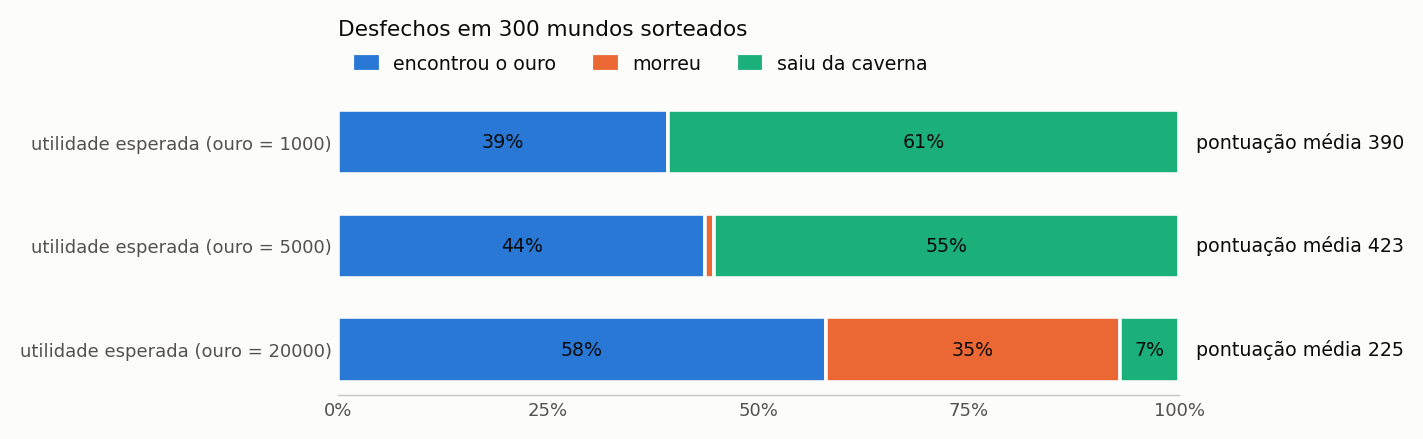

## Exercícios propostos

1. **Prior diferente.** Altere `PIT_PROB` para 0,1 e 0,4 e recalcule as crenças do agente que visitou $[1,1]$, $[1,2]$ e $[2,1]$ e sentiu brisa nas duas últimas. Como as posteriores mudam? E a decisão?
2. **Sensor ruidoso.** Suponha $P(b \mid \text{poço vizinho}) = 0{,}9$ e $P(b \mid \text{nenhum poço vizinho}) = 0{,}05$. Modifique `consistent` para devolver a verossimilhança em vez de 0/1. O que acontece com a certeza de poço em $[1,2]$, deduzida quando o agente sente brisa em $[1,1]$ e nenhuma brisa em $[2,1]$?
3. **Valor da informação.** A decisão atual é míope. Proponha uma estimativa de $P(\text{ouro}_c)$ que considere as salas que se tornam acessíveis depois de explorar $c$.
4. **A flecha.** Quando $P(\text{Wumpus em } c) = 1$, atirar na direção de $c$ elimina o risco. Inclua essa ação na comparação de utilidades.

## Principais conclusões

* **Mundos possíveis e conjunta.** Uma distribuição conjunta completa responde a qualquer pergunta, somando mundos (completude semântica), condicionando (descarte de mundos) e normalizando ($\alpha$).
* **A escala impõe estrutura.** A enumeração custa $O(2^n)$. Independência absoluta (poços) e condicional (brisas dados os poços vizinhos) reduzem a inferência à **fronteira**.
* **Toda a evidência importa.** Bayes aplicado a uma observação isolada erra. Considerar toda a evidência produz efeitos como o *explaining away*.
* **Causal × diagnóstico.** Armazene $P(\text{efeito} \mid \text{causa})$, geralmente mais estável, e obtenha $P(\text{causa} \mid \text{efeito})$ via Bayes. Uma probabilidade condicional, por si só, não prova causalidade.
* **Racionalidade = crença + preferência.** O agente combina probabilidades exatas com utilidades. A mesma crença pode levar a ações diferentes quando as recompensas mudam.

## Referências

* **RUSSELL, Stuart; NORVIG, Peter.** *Artificial Intelligence: A Modern Approach*. 4th ed. Pearson, 2020. Capítulo 12 (*Quantifying Uncertainty*, em especial §12.7, *The Wumpus World Revisited*) e Capítulo 13 (*Probabilistic Reasoning*).
* **POOLE, David L.; MACKWORTH, Alan K.** *Artificial Intelligence: Foundations of Computational Agents*. 2nd ed. Cambridge University Press, 2017.
* **BARBER, David.** *Bayesian Reasoning and Machine Learning*. Cambridge University Press, 2012.